## Stacking mosaic ( MSI)

In [2]:
pip install rasterio

Note: you may need to restart the kernel to use updated packages.


In [28]:
import rasterio
import numpy as np
import glob
import os
import matplotlib.pyplot as plt

### 1. Path to the folder that contains the working directory.

In [19]:
Folder = r"D:\NERF_2023_Watertown\4_index\reflectance" # Chemin ou se trouve le dossier
Files = sorted(glob.glob(Folder + r"\*.tif")) 

In [20]:
for name in sorted(os.listdir(Folder)):
    path = os.path.join(Folder, name)
    size_mb = os.path.getsize(path) / 1e6 if os.path.isfile(path) else 0
    kind = "folder" if os.path.isdir(path) else f"{size_mb:.1f} MB"
    print(f"{name:40s} {kind}")

NERF_2023_Watertown_transparent_reflectance_blue.prj 0.0 MB
NERF_2023_Watertown_transparent_reflectance_blue.tfw 0.0 MB
NERF_2023_Watertown_transparent_reflectance_blue.tif 93.8 MB
NERF_2023_Watertown_transparent_reflectance_green.prj 0.0 MB
NERF_2023_Watertown_transparent_reflectance_green.tfw 0.0 MB
NERF_2023_Watertown_transparent_reflectance_green.tif 92.8 MB
NERF_2023_Watertown_transparent_reflectance_nir.prj 0.0 MB
NERF_2023_Watertown_transparent_reflectance_nir.tfw 0.0 MB
NERF_2023_Watertown_transparent_reflectance_nir.tif 93.0 MB
NERF_2023_Watertown_transparent_reflectance_red edge.prj 0.0 MB
NERF_2023_Watertown_transparent_reflectance_red edge.tfw 0.0 MB
NERF_2023_Watertown_transparent_reflectance_red edge.tif 93.4 MB
NERF_2023_Watertown_transparent_reflectance_red.prj 0.0 MB
NERF_2023_Watertown_transparent_reflectance_red.tfw 0.0 MB
NERF_2023_Watertown_transparent_reflectance_red.tif 94.4 MB
tiles                                    folder


### 2. Check coordinates

In [22]:
print("Files found:", len(Files))
for f in Files:
    with rasterio.open(f) as src:
        print(f.split("\\")[-1])
        print("   size:", src.width, "x", src.height,
              "| bands:", src.count,
              "| type:", src.dtypes[0],
              "| CRS:", src.crs,
              "| pixel:", round(src.res[0], 4))

Files found: 5
NERF_2023_Watertown_transparent_reflectance_blue.tif
   size: 4000 x 7231 | bands: 1 | type: float32 | CRS: EPSG:32614 | pixel: 0.0226
NERF_2023_Watertown_transparent_reflectance_green.tif
   size: 4000 x 7231 | bands: 1 | type: float32 | CRS: EPSG:32614 | pixel: 0.0226
NERF_2023_Watertown_transparent_reflectance_nir.tif
   size: 4000 x 7231 | bands: 1 | type: float32 | CRS: EPSG:32614 | pixel: 0.0226
NERF_2023_Watertown_transparent_reflectance_red edge.tif
   size: 4000 x 7231 | bands: 1 | type: float32 | CRS: EPSG:32614 | pixel: 0.0226
NERF_2023_Watertown_transparent_reflectance_red.tif
   size: 4000 x 7231 | bands: 1 | type: float32 | CRS: EPSG:32614 | pixel: 0.0226


### 3. Stack

In [37]:
prefix = "NERF_2023_Watertown_transparent_reflectance_"
out_path = os.path.join(Folder, "NERF_2023_Watertown_stack.tif")

# Order by wavelength: (file suffix, band name)
order = [("blue", "Blue"),
         ("green", "Green"),
         ("red", "Red"),
         ("red edge", "RedEdge"),
         ("nir", "NIR")]

files = [os.path.join(Folder, f"{prefix}{suffix}.tif") for suffix, _ in order]

with rasterio.open(Files[0]) as ref:
    profile = ref.profile.copy()
profile.update(count=5, compress="lzw", tiled=True, blockxsize=512, blockysize=512)

with rasterio.open(out_path, "w", **profile) as dst:
    for i, (path, (_, name)) in enumerate(zip(files, order), start=1):
        with rasterio.open(path) as src:
            dst.write(src.read(1), i)
        dst.set_band_description(i, name)
        print(f"band {i} = {name:8s} <- {os.path.basename(path)}")

print("Saved:", out_path)

band 1 = Blue     <- NERF_2023_Watertown_transparent_reflectance_blue.tif
band 2 = Green    <- NERF_2023_Watertown_transparent_reflectance_green.tif
band 3 = Red      <- NERF_2023_Watertown_transparent_reflectance_red.tif
band 4 = RedEdge  <- NERF_2023_Watertown_transparent_reflectance_red edge.tif
band 5 = NIR      <- NERF_2023_Watertown_transparent_reflectance_nir.tif
Saved: D:\NERF_2023_Watertown\4_index\reflectance\NERF_2023_Watertown_stack.tif


### 4. Spectral profile 

Valid pixels used: 245103
Blue     mean = 0.024  std = 0.010
Green    mean = 0.057  std = 0.018
Red      mean = 0.059  std = 0.041
RedEdge  mean = 0.111  std = 0.034
NIR      mean = 0.439  std = 0.144


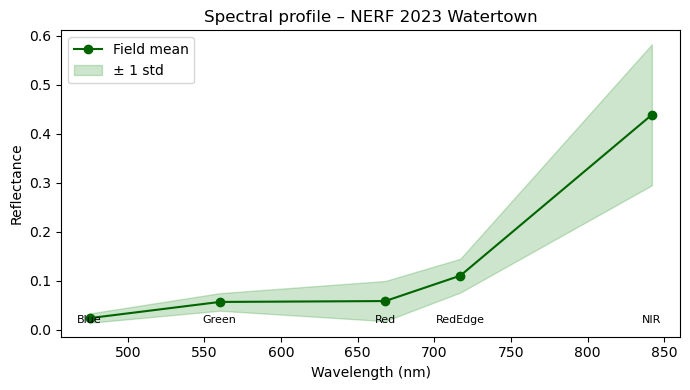

In [32]:
stack_path = r"D:\NERF_2023_Watertown\4_index\reflectance\NERF_2023_Watertown_stack.tif"
# Altum center wavelengths (nm), same order as the stack
wavelengths = [475, 560, 668, 717, 842]
names = ["Blue", "Green", "Red", "RedEdge", "NIR"]

with rasterio.open(stack_path) as src:
    data = src.read(out_shape=(src.count, src.height // 10, src.width // 10))

pixels = data.reshape(5, -1)
valid = np.all((pixels > 0) & (pixels < 1), axis=0)   # remove nodata/edges
pixels = pixels[:, valid]
print("Valid pixels used:", pixels.shape[1])

mean = pixels.mean(axis=1)
std = pixels.std(axis=1)
for n, m, s in zip(names, mean, std):
    print(f"{n:8s} mean = {m:.3f}  std = {s:.3f}")

plt.figure(figsize=(7, 4))
plt.plot(wavelengths, mean, "o-", color="darkgreen", label="Field mean")
plt.fill_between(wavelengths, mean - std, mean + std, color="green", alpha=0.2, label="± 1 std")
for w, n in zip(wavelengths, names):
    plt.annotate(n, (w, 0), textcoords="offset points", xytext=(0, 5), ha="center", fontsize=8)
plt.xlabel("Wavelength (nm)")
plt.ylabel("Reflectance")
plt.title("Spectral profile – NERF 2023 Watertown")
plt.legend()
plt.tight_layout()
plt.savefig(stack_path.replace(".tif", "_spectral_profile.png"), dpi=300)
plt.show()

### 5. Reflectance

In [36]:
with rasterio.open(stack_path) as src:
    data = src.read(out_shape=(src.count, src.height // 10, src.width // 10))
    names = src.descriptions
    print("nodata value:", src.nodata)

for i, name in enumerate(names):
    band = data[i].ravel()
    band = band[np.isfinite(band)]
    print(f"\n{name}")
    print(f"   min = {band.min():.4f}   max = {band.max():.4f}")
    print(f"   2% = {np.percentile(band, 2):.4f}   median = {np.median(band):.4f}   98% = {np.percentile(band, 98):.4f}")
    print(f"   pixels < 0: {(band < 0).mean()*100:.1f}%   pixels > 1: {(band > 1).mean()*100:.1f}%")

nodata value: -10000.0

Blue
   min = -10000.0000   max = 0.0817
   2% = -10000.0000   median = 0.0199   98% = 0.0454
   pixels < 0: 15.2%   pixels > 1: 0.0%

Green
   min = -10000.0000   max = 0.1478
   2% = -10000.0000   median = 0.0505   98% = 0.0949
   pixels < 0: 15.2%   pixels > 1: 0.0%

Red
   min = -10000.0000   max = 0.3853
   2% = -10000.0000   median = 0.0340   98% = 0.1427
   pixels < 0: 15.1%   pixels > 1: 0.0%

RedEdge
   min = -10000.0000   max = 0.2924
   2% = -10000.0000   median = 0.0983   98% = 0.1816
   pixels < 0: 15.1%   pixels > 1: 0.0%

NIR
   min = -10000.0000   max = 0.9314
   2% = -10000.0000   median = 0.3770   98% = 0.7449
   pixels < 0: 15.0%   pixels > 1: 0.0%
